# 01 · Perfilado de calidad de los datos (fase *Prepare*)

**Proyecto:** De los datos a la toma de decisiones — viajes de ECOBICI CDMX, enero 2024 a diciembre 2025.

**Objetivo de este notebook:** antes de analizar nada, revisar **qué tan confiables son los datos**.
Es como revisar los ingredientes antes de cocinar: contamos cuántos registros hay, si faltan valores,
si hay edades imposibles, viajes que "terminan antes de empezar", estaciones con códigos raros, etc.

**Importante:** aquí **no se corrige ni se borra nada**. Solo se mide y se documenta. Las decisiones de
limpieza se toman en `02_limpieza.ipynb` y se registran en `docs/bitacora_decisiones.md`.

**Fuente:** https://ecobici.cdmx.gob.mx/datos-abiertos/ (descargados con `descargar_ecobici.sh`).
Un archivo CSV por mes en `datos/raw/AAAA-MM.csv`.

## 1. Preparación

Cargamos las librerías y definimos las rutas **relativas** a la carpeta del proyecto, para que el notebook
funcione igual en la computadora de cualquier integrante del equipo.

Le damos a las columnas nombres cortos y uniformes (por ejemplo `genero`, `edad`, `est_retiro`), porque
algunos meses escriben los encabezados distinto (con comillas o con espacios).

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# La raíz del proyecto es la carpeta que contiene a notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = RAIZ / "datos" / "raw"
PERFIL = RAIZ / "datos" / "perfil"
FIGURAS = RAIZ / "figuras"
PERFIL.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

# Nombres originales "normalizados" -> nombre corto que usaremos
COLUMNAS = {
    "genero_usuario": "genero",
    "edad_usuario": "edad",
    "bici": "bici",
    "ciclo_estacion_retiro": "est_retiro",
    "fecha_retiro": "fecha_retiro",
    "hora_retiro": "hora_retiro",
    "ciclo_estacionarribo": "est_arribo",
    "fecha_arribo": "fecha_arribo",
    "hora_arribo": "hora_arribo",
}

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

archivos = sorted(RAW.glob("*.csv"))
print(f"Carpeta de datos: {RAW.relative_to(RAIZ)}")
print(f"Archivos encontrados: {len(archivos)}  ({archivos[0].stem} a {archivos[-1].stem})")
print(f"Tamaño total: {sum(f.stat().st_size for f in archivos) / 1e9:.2f} GB")

Carpeta de datos: datos/raw
Archivos encontrados: 24  (2024-01 a 2025-12)
Tamaño total: 2.66 GB


## 2. ¿Todos los archivos tienen las mismas columnas?

Si un mes trae columnas distintas (otro nombre, otro orden o una columna de más), al juntarlos se
mezclarían datos sin darnos cuenta. Por eso revisamos el encabezado **original** de cada archivo y
comprobamos que, una vez quitadas comillas y espacios, todos tienen las mismas 9 columnas en el mismo orden.

In [2]:
def normalizar(nombre):
    """Quita comillas y espacios y pasa a minúsculas: '"Fecha Arribo"' -> 'fecha_arribo'."""
    return nombre.strip().strip('"').strip().replace(" ", "_").lower()

encabezados = []
for f in archivos:
    with open(f, encoding="utf-8") as fh:
        crudo = fh.readline().rstrip("\r\n")
    nombres = [normalizar(c) for c in crudo.split(",")]
    encabezados.append({
        "mes": f.stem,
        "num_columnas": len(nombres),
        "con_comillas": '"' in crudo,
        "fecha_arribo_con_espacio": "Fecha Arribo" in crudo,
        "columnas_coinciden": nombres == list(COLUMNAS),
    })
encabezados = pd.DataFrame(encabezados)
encabezados

,mes,num_columnas,con_comillas,fecha_arribo_con_espacio,columnas_coinciden
0,2024-01,9,True,True,True
1,2024-02,9,True,True,True
2,2024-03,9,True,True,True
3,2024-04,9,False,False,True
4,2024-05,9,True,True,True
5,2024-06,9,True,True,True
6,2024-07,9,True,True,True
7,2024-08,9,True,False,True
8,2024-09,9,True,False,True
9,2024-10,9,False,False,True


In [3]:
assert encabezados["columnas_coinciden"].all(), "¡Algún mes tiene columnas distintas! Revisar antes de seguir."
print("Todos los meses tienen las mismas 9 columnas en el mismo orden (tras normalizar nombres).")
print("Meses con encabezados entre comillas:", encabezados.loc[encabezados.con_comillas, "mes"].tolist())
print("Meses con 'Fecha Arribo' (con espacio):", encabezados.loc[encabezados.fecha_arribo_con_espacio, "mes"].tolist())

Todos los meses tienen las mismas 9 columnas en el mismo orden (tras normalizar nombres).
Meses con encabezados entre comillas: ['2024-01', '2024-02', '2024-03', '2024-05', '2024-06', '2024-07', '2024-08', '2024-09']
Meses con 'Fecha Arribo' (con espacio): ['2024-01', '2024-02', '2024-03', '2024-05', '2024-06', '2024-07']


## 3. Revisión de calidad mes por mes

Son unos **42 millones de viajes** (≈2.7 GB). Para no saturar la memoria de una laptop, leemos **un mes a la vez**,
calculamos sus indicadores de calidad y pasamos al siguiente.

Leemos **todo como texto**. Así vemos los datos tal como vienen: si una edad dice "abc" o un código de estación
es "015", no se pierde ni se transforma (si se leyera como número, "015" se volvería 15 y "abc" desaparecería).

Para cada mes medimos:

| Indicador | Qué significa | Por qué importa |
|---|---|---|
| filas | número de viajes | ver si algún mes está incompleto |
| vacíos / "NULL" | celdas sin dato | datos faltantes sesgan los resultados |
| género | conteo de M, F, O, "?" y "NULL" | base para cualquier análisis por género |
| edad | mínima, máxima, no numéricas, mayores de 80 | detectar edades imposibles o capturadas mal |
| formato de fecha/hora | si todas siguen dd/mm/aaaa y HH:MM:SS | un formato distinto rompe los cálculos de tiempo |
| duración | negativas, < 1 min, > 24 h, mediana | viajes imposibles o sospechosos |
| fechas fuera del mes | retiros de meses anteriores, arribos de otro mes | entender cómo está organizado cada archivo |
| misma estación | el viaje empieza y termina en la misma estación | pueden ser paseos… o bicis devueltas por falla |
| estaciones | cuántas distintas y si hay códigos no numéricos | detectar códigos raros como "271-272" |
| duplicados | filas idénticas repetidas | contarían doble un mismo viaje |

Además guardamos los conteos de **edades** y un histograma de **duraciones** para graficarlos después,
usando *todos* los viajes, no una muestra.

In [4]:
# Cortes del histograma de duración (en minutos), en escala logarítmica: de 1 segundo a ~4 años
CORTES_DUR = np.logspace(np.log10(1/60), np.log10(2.1e6), 141)

def a_fecha_hora(fecha, hora):
    """Une fecha y hora (texto) y las convierte a fecha-hora. Lo que no se pueda leer queda vacío (NaT)."""
    return pd.to_datetime(fecha + " " + hora, format="%d/%m/%Y %H:%M:%S", errors="coerce")

def perfilar_mes(ruta):
    mes = ruta.stem
    df = pd.read_csv(ruta, dtype=str, header=0, names=list(COLUMNAS.values()),
                     keep_default_na=False, encoding="utf-8")
    p = {"mes": mes, "filas": len(df)}

    # --- Vacíos y "NULL" (en todas las columnas) ---
    p["celdas_vacias"] = int(sum((df[c].str.strip() == "").sum() for c in df.columns))
    p["celdas_NULL"] = int(sum((df[c].str.strip().str.upper() == "NULL").sum() for c in df.columns))

    # --- Género ---
    g = df["genero"].str.strip()
    for v in ["M", "F", "O", "?", "NULL"]:
        p[f"genero_{v}"] = int((g == v).sum())
    p["genero_otro_valor"] = int((~g.isin(["M", "F", "O", "?", "NULL"])).sum())

    # --- Edad ---
    edad_txt = df["edad"].str.strip()
    edad = pd.to_numeric(edad_txt, errors="coerce")
    p["edad_min"] = edad.min()
    p["edad_max"] = edad.max()
    p["edad_mediana"] = edad.median()
    p["edad_no_numerica"] = int(edad.isna().sum())
    p["edad_menor_16"] = int((edad < 16).sum())
    p["edad_mayor_80"] = int((edad > 80).sum())
    no_num = edad_txt[edad.isna()].value_counts().head(3)
    p["edad_ejemplos_no_num"] = ", ".join(f"'{k}'({v})" for k, v in no_num.items())
    conteo_edad = edad.dropna().astype(int).value_counts()

    # --- Bici ---
    p["bici_no_numerica"] = int((~df["bici"].str.fullmatch(r"\d+")).sum())
    p["bicis_unicas"] = df["bici"].nunique()

    # --- Formatos de fecha y hora ---
    p["fecha_formato_raro"] = int(sum((~df[c].str.fullmatch(r"\d{2}/\d{2}/\d{4}")).sum()
                                      for c in ["fecha_retiro", "fecha_arribo"]))
    p["hora_formato_raro"] = int(sum((~df[c].str.fullmatch(r"\d{2}:\d{2}:\d{2}")).sum()
                                     for c in ["hora_retiro", "hora_arribo"]))

    # --- Duración ---
    retiro = a_fecha_hora(df["fecha_retiro"], df["hora_retiro"])
    arribo = a_fecha_hora(df["fecha_arribo"], df["hora_arribo"])
    p["fecha_no_legible"] = int((retiro.isna() | arribo.isna()).sum())
    dur = (arribo - retiro).dt.total_seconds() / 60
    p["dur_negativa"] = int((dur < 0).sum())
    p["dur_cero"] = int((dur == 0).sum())
    p["dur_menor_1min"] = int(((dur > 0) & (dur < 1)).sum())
    p["dur_mayor_3h"] = int((dur > 180).sum())
    p["dur_mayor_24h"] = int((dur > 1440).sum())
    p["dur_mediana_min"] = round(dur.median(), 2)
    p["dur_max_dias"] = round(dur.max() / 1440, 1)
    hist_dur, _ = np.histogram(dur[dur > 0].clip(upper=CORTES_DUR[-1] * 0.999), bins=CORTES_DUR)

    # --- Fechas fuera del mes del archivo ---
    inicio = pd.Timestamp(f"{mes}-01")
    fin = inicio + pd.offsets.MonthBegin(1)
    p["retiro_min"] = retiro.min()
    p["retiro_antes_del_mes"] = int((retiro < inicio).sum())
    p["retiro_antes_2024"] = int((retiro < pd.Timestamp("2024-01-01")).sum())
    p["arribo_fuera_del_mes"] = int(((arribo < inicio) | (arribo >= fin)).sum())

    # --- Estaciones ---
    p["misma_estacion"] = int((df["est_retiro"] == df["est_arribo"]).sum())
    estaciones = pd.concat([df["est_retiro"], df["est_arribo"]]).str.strip()
    p["estaciones_unicas"] = estaciones.nunique()
    no_num_est = estaciones[~estaciones.str.fullmatch(r"\d+")]
    p["viajes_est_no_numerica"] = int((~df["est_retiro"].str.fullmatch(r"\d+")).sum()
                                     + (~df["est_arribo"].str.fullmatch(r"\d+")).sum())
    p["codigos_no_numericos"] = ", ".join(sorted(no_num_est.unique()))
    p["codigos_sin_cero_izq"] = int((estaciones.str.fullmatch(r"\d{1,2}")).sum())  # p.ej. "15" en vez de "015"

    # --- Duplicados exactos ---
    p["duplicados_exactos"] = int(df.duplicated().sum())

    return p, conteo_edad, hist_dur, set(estaciones.unique())

Ahora recorremos los 24 meses. Tarda unos minutos; se imprime una línea por mes para ver el avance.

In [5]:
import time
resumen, conteos_edad, hist_dur_total, todas_estaciones = [], [], np.zeros(len(CORTES_DUR) - 1), set()
t0 = time.time()
for ruta in archivos:
    p, ce, hd, est = perfilar_mes(ruta)
    resumen.append(p)
    conteos_edad.append(ce)
    hist_dur_total += hd
    todas_estaciones |= est
    print(f"{p['mes']}: {p['filas']:>10,} viajes   ({time.time() - t0:5.0f} s acumulados)")

calidad = pd.DataFrame(resumen).set_index("mes")
edades = pd.concat(conteos_edad, axis=1).fillna(0).sum(axis=1).sort_index()
print(f"\nTotal de viajes: {calidad['filas'].sum():,}")

2024-01:  1,558,100 viajes   (    7 s acumulados)


2024-02:  1,699,409 viajes   (   14 s acumulados)


2024-03:  1,829,763 viajes   (   21 s acumulados)


2024-04:  1,961,633 viajes   (   30 s acumulados)


2024-05:  2,053,563 viajes   (   38 s acumulados)


2024-06:  1,893,520 viajes   (   46 s acumulados)


... (14 outputs left out)

2025-09:  1,586,508 viajes   (  158 s acumulados)


2025-10:  1,754,353 viajes   (  166 s acumulados)


2025-11:  1,600,741 viajes   (  172 s acumulados)


2025-12:  1,445,068 viajes   (  178 s acumulados)

Total de viajes: 42,377,769


## 4. Tabla resumen de calidad por mes

Esta es la evidencia principal del diagnóstico. Cada renglón es un mes y cada columna un indicador.
La guardamos también como `datos/perfil/calidad_por_mes.csv` para poder citarla en el documento final.

La mostramos en bloques temáticos para que se lea mejor.

In [6]:
calidad.to_csv(PERFIL / "calidad_por_mes.csv")
print("Guardado:", (PERFIL / "calidad_por_mes.csv").relative_to(RAIZ))

print("\n### Volumen, vacíos y género")
display(calidad[["filas", "celdas_vacias", "celdas_NULL", "genero_M", "genero_F", "genero_O",
                 "genero_?", "genero_NULL", "genero_otro_valor"]])

Guardado: datos/perfil/calidad_por_mes.csv

### Volumen, vacíos y género


,filas,celdas_vacias,celdas_NULL,genero_M,genero_F,genero_O,genero_?,genero_NULL,genero_otro_valor
mes,,,,,,,,,
2024-01,1558100,0,5,1087342,439529,31220,9,0,0
2024-02,1699409,0,28,1178015,486873,34496,13,12,0
2024-03,1829763,0,27,1254720,538382,36646,10,5,0
2024-04,1961633,0,16,1351575,572505,37548,4,1,0
2024-05,2053563,0,25,1415997,598398,39142,19,7,0
2024-06,1893520,0,10,1307283,549349,36875,10,3,0
2024-07,1825650,0,24,1268543,521061,36021,16,9,0
2024-08,1891319,0,36,1310835,543338,37112,19,15,0
2024-09,1852179,0,49,1279444,537290,35403,25,17,0


In [7]:
print("### Edad")
display(calidad[["edad_min", "edad_max", "edad_mediana", "edad_no_numerica", "edad_ejemplos_no_num",
                 "edad_menor_16", "edad_mayor_80"]])

### Edad


,edad_min,edad_max,edad_mediana,edad_no_numerica,edad_ejemplos_no_num,edad_menor_16,edad_mayor_80
mes,,,,,,,
2024-01,16.0,101.0,32.0,5,'NULL'(5),0,178
2024-02,16.0,101.0,32.0,16,'NULL'(16),0,295
2024-03,16.0,124.0,32.0,22,'NULL'(22),0,507
2024-04,16.0,160.0,32.0,15,'NULL'(15),0,409
2024-05,16.0,123.0,32.0,18,'NULL'(18),0,276
2024-06,16.0,102.0,32.0,7,'NULL'(7),0,221
2024-07,16.0,102.0,32.0,15,'NULL'(15),0,234
2024-08,16.0,104.0,32.0,21,'NULL'(21),0,273
2024-09,16.0,102.0,32.0,32,'NULL'(32),0,249


In [8]:
print("### Fechas y duración (minutos)")
display(calidad[["fecha_formato_raro", "hora_formato_raro", "fecha_no_legible", "dur_mediana_min",
                 "dur_negativa", "dur_cero", "dur_menor_1min", "dur_mayor_3h", "dur_mayor_24h", "dur_max_dias",
                 "retiro_min", "retiro_antes_del_mes", "retiro_antes_2024", "arribo_fuera_del_mes"]])

### Fechas y duración (minutos)


,fecha_formato_raro,hora_formato_raro,fecha_no_legible,dur_mediana_min,dur_negativa,dur_cero,dur_menor_1min,dur_mayor_3h,dur_mayor_24h,dur_max_dias,retiro_min,retiro_antes_del_mes,retiro_antes_2024,arribo_fuera_del_mes
mes,,,,,,,,,,,,,,
2024-01,0,0,0,12.28,0,0,85,681,38,190.7,2023-07-15 22:36:10,83,83,0
2024-02,0,0,0,12.38,0,0,110,867,42,207.3,2023-08-01 14:20:15,151,1,0
2024-03,0,0,0,12.52,0,0,117,1037,42,142.8,2023-10-25 19:24:11,217,3,0
2024-04,0,0,0,12.38,0,0,129,725,35,341.2,2023-05-06 12:09:30,116,5,0
2024-05,0,0,0,12.17,0,0,135,854,46,550.0,2022-11-05 13:12:09,230,3,0
2024-06,0,0,0,12.10,0,0,140,742,55,611.5,2022-10-07 15:29:21,357,6,0
2024-07,0,0,0,11.98,0,0,111,717,39,470.2,2023-03-27 16:09:20,68,2,0
2024-08,0,0,0,12.00,0,0,147,842,95,736.0,2022-08-19 14:44:45,202,2,0
2024-09,0,0,0,12.18,0,0,152,800,61,119.6,2024-05-07 20:32:17,245,0,0


In [9]:
print("### Estaciones, bicis y duplicados")
display(calidad[["estaciones_unicas", "misma_estacion", "viajes_est_no_numerica", "codigos_no_numericos",
                 "codigos_sin_cero_izq", "bicis_unicas", "bici_no_numerica", "duplicados_exactos"]])

### Estaciones, bicis y duplicados


,estaciones_unicas,misma_estacion,viajes_est_no_numerica,codigos_no_numericos,codigos_sin_cero_izq,bicis_unicas,bici_no_numerica,duplicados_exactos
mes,,,,,,,,
2024-01,655,42500,148277,"107-108, 158-159, 192-193, 235-236, 237-238, 2...",0,8354,0,0
2024-02,662,45483,157400,"107-108, 158-159, 192-193, 235-236, 237-238, 2...",0,8278,0,0
2024-03,666,52850,163949,"107-108, 158-159, 192-193, 235-236, 237-238, 2...",0,8201,0,0
2024-04,668,52239,181927,"107-108, 158-159, 192-193, 235-236, 237-238, 2...",0,8464,0,0
2024-05,667,55816,190560,"107-108, 158-159, 192-193, 235-236, 237-238, 2...",0,8400,0,0
2024-06,672,52680,178465,"107-108, 158-159, 192-193, 235-236, 237-238, 2...",0,8342,0,0
2024-07,677,49896,174201,"107-108, 158-159, 192-193, 235-236, 237-238, 2...",0,8238,0,0
2024-08,679,52521,172878,"107-108, 158-159, 192-193, 235-236, 237-238, 2...",0,8199,0,0
2024-09,678,51687,173457,"107-108, 158-159, 192-193, 235-236, 237-238, 2...",0,8153,0,0


### Totales de los 24 meses

Sumamos los conteos de todos los meses y los expresamos también como **porcentaje del total de viajes**.
Esto ayuda a decidir después qué tan grave es cada problema: no es lo mismo un problema en 100 viajes
que en 1 millón.

In [10]:
cols_conteo = ["celdas_vacias", "celdas_NULL", "genero_?", "genero_NULL", "genero_otro_valor",
               "edad_no_numerica", "edad_menor_16", "edad_mayor_80", "bici_no_numerica",
               "fecha_formato_raro", "hora_formato_raro", "fecha_no_legible",
               "dur_negativa", "dur_cero", "dur_menor_1min", "dur_mayor_3h", "dur_mayor_24h",
               "retiro_antes_del_mes", "retiro_antes_2024", "arribo_fuera_del_mes",
               "misma_estacion", "viajes_est_no_numerica", "duplicados_exactos"]
total_viajes = calidad["filas"].sum()
totales = pd.DataFrame({"total": calidad[cols_conteo].sum()})
totales["% de viajes"] = (100 * totales["total"] / total_viajes).round(4)
genero_total = calidad[["genero_M", "genero_F", "genero_O", "genero_?", "genero_NULL"]].sum()

print(f"Viajes totales: {total_viajes:,}")
print(f"Estaciones distintas (24 meses): {len(todas_estaciones)}")
print("Códigos de estación no numéricos:", sorted(e for e in todas_estaciones if not e.isdigit()))
print(f"Edad: mínimo {calidad['edad_min'].min():.0f}, máximo {calidad['edad_max'].max():.0f}")
print(f"Duración mediana por mes: entre {calidad['dur_mediana_min'].min()} y {calidad['dur_mediana_min'].max()} min")
print(f"Retiro más antiguo: {calidad['retiro_min'].min()}")
print("\nGénero (% del total):", (100 * genero_total / total_viajes).round(2).to_dict())
totales

Viajes totales: 42,377,769
Estaciones distintas (24 meses): 681
Códigos de estación no numéricos: ['107-108', '158-159', '192-193', '235-236', '237-238', '264-275', '266-267', '268-269', '271-272', '273-274', '390-391', '445-446', 'Temporal - 2da Sección Bosque Chapultepec', 'tag 2']
Edad: mínimo 16, máximo 160
Duración mediana por mes: entre 11.67 y 12.52 min
Retiro más antiguo: 2022-08-19 14:44:45

Género (% del total): {'genero_M': 68.65, 'genero_F': 28.3, 'genero_O': 1.93, 'genero_?': 1.12, 'genero_NULL': 0.0}


,total,% de viajes
celdas_vacias,0,0.0000
celdas_NULL,1907,0.0045
genero_?,475613,1.1223
genero_NULL,119,0.0003
genero_otro_valor,0,0.0000
edad_no_numerica,1788,0.0042
edad_menor_16,0,0.0000
edad_mayor_80,9169,0.0216
bici_no_numerica,0,0.0000
fecha_formato_raro,0,0.0000


## 5. Gráficas de calidad

Cuatro gráficas sencillas para **ver** lo que dicen las tablas:

1. **Viajes por mes**: ¿hay meses con huecos o caídas extrañas que indiquen datos incompletos?
2. **Género por mes**: ¿cambia la proporción de cada categoría, sobre todo la de "?" (sin dato)?
3. **Distribución de edad**: ¿hay edades imposibles?
4. **Distribución de duración**: ¿cuántos viajes son demasiado cortos o demasiado largos?

Se guardan en la carpeta `figuras/` para usarlas en el documento.

In [11]:
# Estilo común: colores de una paleta probada para daltonismo, ejes discretos
AZUL, NARANJA, AQUA, GRIS, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
    "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2, "text.color": TINTA,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10,
})
miles = mticker.FuncFormatter(lambda x, _: f"{x/1e6:g} M" if x >= 1e6 else f"{x:,.0f}")

### 5.1 Viajes por mes

Cada barra es un mes. Si algún archivo estuviera incompleto (por ejemplo, con solo la mitad de los días),
se vería como una barra mucho más baja que sus vecinas. Variaciones moderadas son normales
(vacaciones, lluvias, días festivos).

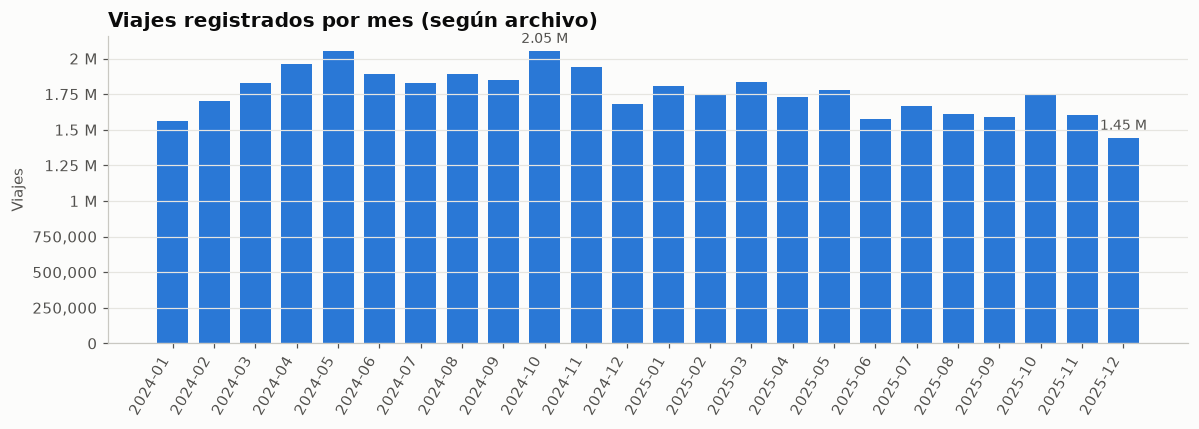

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(calidad))
ax.bar(x, calidad["filas"], color=AZUL, width=0.75)
ax.set_xticks(x, calidad.index, rotation=60, ha="right")
ax.yaxis.set_major_formatter(miles)
ax.set_ylabel("Viajes")
ax.set_title("Viajes registrados por mes (según archivo)")
for i in [calidad["filas"].values.argmin(), calidad["filas"].values.argmax()]:
    ax.annotate(f"{calidad['filas'].iloc[i]/1e6:.2f} M", (i, calidad["filas"].iloc[i]),
                ha="center", va="bottom", fontsize=9, color=TINTA2, xytext=(0, 3), textcoords="offset points")
fig.tight_layout()
fig.savefig(FIGURAS / "01_viajes_por_mes.png")
plt.show()

### 5.2 Género por mes

Mostramos el porcentaje de viajes de cada categoría de género. Lo que más nos interesa vigilar es la
categoría **"?"** (y "NULL"): son viajes **sin dato de género**. Si crece con el tiempo, cualquier análisis
por género de los meses recientes será menos confiable. Como "?" y "O" son porcentajes muy pequeños
junto a M y F, se muestran en un segundo panel con su propia escala.

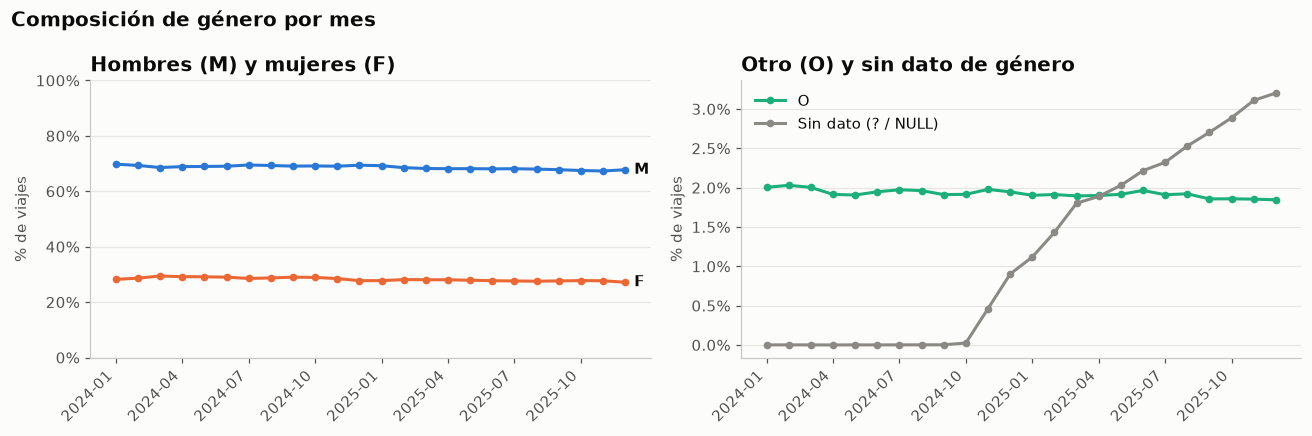

mes,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
genero_M,69.79,69.32,68.57,68.90,68.95,69.04,69.48,69.31,69.08,69.15,69.05,69.40,69.23,68.53,68.22,68.15,68.16,68.09,68.13,68.00,67.79,67.50,67.32,67.77
genero_F,28.21,28.65,29.42,29.19,29.14,29.01,28.54,28.73,29.01,28.91,28.51,27.75,27.75,28.13,28.08,28.06,27.89,27.73,27.64,27.55,27.65,27.76,27.71,27.18
genero_O,2.00,2.03,2.00,1.91,1.91,1.95,1.97,1.96,1.91,1.92,1.98,1.95,1.90,1.91,1.89,1.90,1.92,1.96,1.91,1.92,1.86,1.86,1.85,1.85
sin dato (? + NULL),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.03,0.46,0.90,1.12,1.43,1.80,1.89,2.03,2.22,2.32,2.53,2.70,2.89,3.11,3.20


In [13]:
pct = 100 * calidad[["genero_M", "genero_F", "genero_O"]].div(calidad["filas"], axis=0)
pct["sin dato (? + NULL)"] = 100 * (calidad["genero_?"] + calidad["genero_NULL"]) / calidad["filas"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for col, nombre, color in [("genero_M", "M", AZUL), ("genero_F", "F", NARANJA)]:
    a1.plot(x, pct[col], color=color, lw=2, marker="o", ms=4)
    a1.annotate(nombre, (x[-1], pct[col].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=TINTA, fontweight="bold")
a1.set_ylim(0, 100); a1.set_ylabel("% de viajes")
a1.set_title("Hombres (M) y mujeres (F)")
for col, nombre, color in [("genero_O", "O", AQUA), ("sin dato (? + NULL)", "Sin dato (? / NULL)", GRIS)]:
    a2.plot(x, pct[col], color=color, lw=2, marker="o", ms=4, label=nombre)
a2.set_ylabel("% de viajes"); a2.set_title("Otro (O) y sin dato de género")
a2.legend(frameon=False, loc="upper left")
for a in (a1, a2):
    a.set_xticks(x[::3], calidad.index[::3], rotation=45, ha="right")
    a.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0 if a is a1 else 1))
fig.suptitle("Composición de género por mes", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURAS / "01_genero_por_mes.png")
plt.show()
pct.round(2).T

### 5.3 Distribución de edad

La gráfica cuenta cuántos viajes hay para cada edad (de los 24 meses juntos). La línea punteada marca 80 años:
a partir de ahí los casos son muy raros, y edades de más de 100 años casi seguro son errores de captura.
El eje vertical está en escala logarítmica para que los pocos casos extremos sean visibles junto a los millones de casos normales.

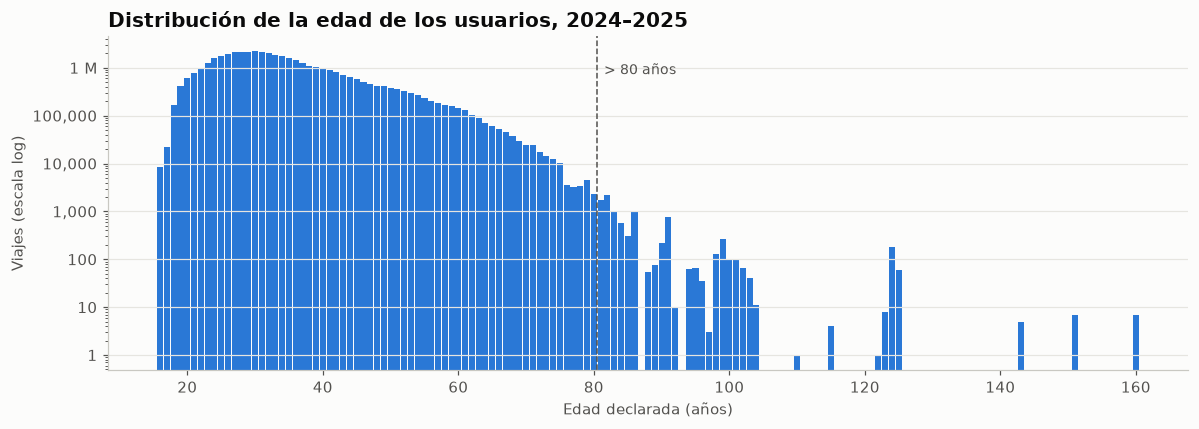

Viajes con edad > 80: 9,169
Viajes con edad > 100: 493
Edades > 100 encontradas: {101: 101, 102: 66, 103: 40, 104: 11, 110: 1, 115: 4, 122: 1, 123: 8, 124: 181, 125: 61, 143: 5, 151: 7, 160: 7}


In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(edades.index, edades.values, width=0.9, color=AZUL)
ax.axvline(80.5, color=TINTA2, ls="--", lw=1)
ax.text(81.5, edades.max() / 3, "> 80 años", color=TINTA2, fontsize=9)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(miles)
ax.set_xlabel("Edad declarada (años)"); ax.set_ylabel("Viajes (escala log)")
ax.set_title("Distribución de la edad de los usuarios, 2024–2025")
fig.tight_layout()
fig.savefig(FIGURAS / "01_distribucion_edad.png")
plt.show()

print(f"Viajes con edad > 80: {int(edades[edades.index > 80].sum()):,}")
print(f"Viajes con edad > 100: {int(edades[edades.index > 100].sum()):,}")
print("Edades > 100 encontradas:", edades[edades.index > 100].astype(int).to_dict())

### 5.4 Distribución de la duración de los viajes

La duración es *hora de llegada − hora de salida*. Usamos **escala logarítmica** en el eje horizontal
porque los valores van de segundos a días: así se ven en una sola gráfica los viajes normales (de 5 a 30 min)
y los extremos. Las líneas punteadas marcan **1 minuto** (posibles arrepentimientos o errores al retirar la bici)
y **24 horas** (posibles bicis no devueltas a tiempo o errores de registro).
Los viajes con duración negativa o cero no caben en una escala logarítmica; se reportan en la tabla.

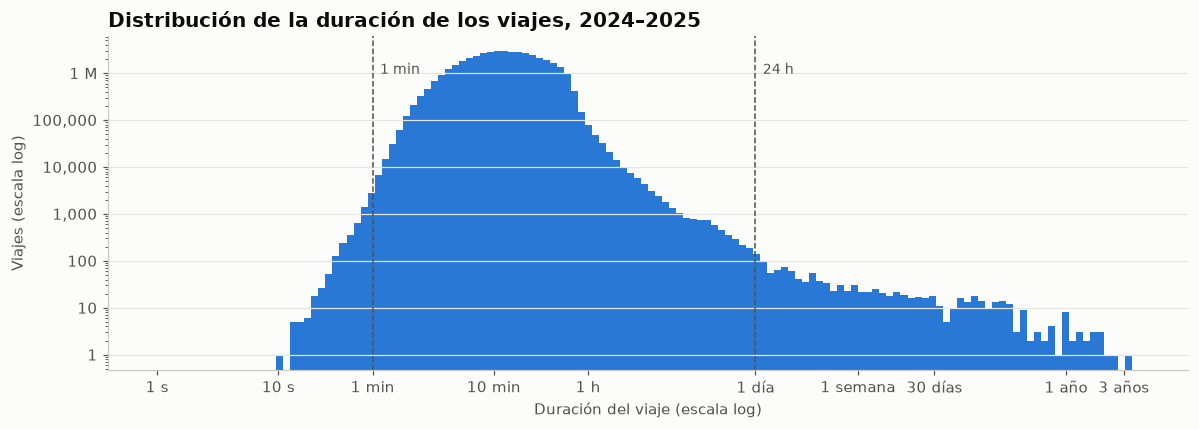

Viajes con duración > 0 (los que aparecen en la gráfica): 42,377,769
  < 1 min: 4,425   |   > 24 h: 1,164   (cifras exactas de la tabla)


In [15]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(CORTES_DUR[:-1], hist_dur_total, width=np.diff(CORTES_DUR), align="edge", color=AZUL)
ax.set_xscale("log"); ax.set_yscale("log")
for v, txt in [(1, "1 min"), (1440, "24 h")]:
    ax.axvline(v, color=TINTA2, ls="--", lw=1)
    ax.text(v * 1.15, hist_dur_total.max() / 3, txt, color=TINTA2, fontsize=9)
marcas = {1/60: "1 s", 10/60: "10 s", 1: "1 min", 10: "10 min", 60: "1 h", 1440: "1 día",
          10080: "1 semana", 43200: "30 días", 525600: "1 año", 1576800: "3 años"}
ax.set_xticks(list(marcas), list(marcas.values()))
ax.xaxis.set_minor_locator(mticker.NullLocator())
ax.yaxis.set_major_formatter(miles)
ax.set_xlabel("Duración del viaje (escala log)"); ax.set_ylabel("Viajes (escala log)")
ax.set_title("Distribución de la duración de los viajes, 2024–2025")
fig.tight_layout()
fig.savefig(FIGURAS / "01_distribucion_duracion.png")
plt.show()

print(f"Viajes con duración > 0 (los que aparecen en la gráfica): {hist_dur_total.sum():,.0f}")
print(f"  < 1 min: {calidad['dur_menor_1min'].sum():,}   |   > 24 h: {calidad['dur_mayor_24h'].sum():,}   (cifras exactas de la tabla)")

## 6. Problemas de calidad encontrados

La siguiente celda arma automáticamente la lista de problemas con su **magnitud real** (calculada arriba),
para que las cifras siempre coincidan con los datos si alguien vuelve a ejecutar el notebook.

Recordatorio: en esta fase **solo se diagnostica**. Qué hacer con cada problema (eliminar, marcar, corregir
o dejar igual) se decide y justifica en `02_limpieza.ipynb` y en `docs/bitacora_decisiones.md`.

In [16]:
T = totales["total"]
pctv = lambda n: f"{100 * n / total_viajes:.3f}%"
def rango(col):
    return f"{calidad[col].min():,}–{calidad[col].max():,} por mes"

meses_comillas = encabezados.loc[encabezados.con_comillas, "mes"].tolist()
meses_espacio = encabezados.loc[encabezados.fecha_arribo_con_espacio, "mes"].tolist()
q = calidad["genero_?"]
cod_raros = sorted(e for e in todas_estaciones if not e.isdigit())

problemas = [
    ("Encabezados inconsistentes",
     f"Comillas en {', '.join(meses_comillas) or 'ninguno'}; 'Fecha Arribo' con espacio en {len(meses_espacio)} meses. "
     "Se resuelve al leer (se renombran columnas); no afecta registros."),
    ("Género sin dato ('?')",
     f"{int(T['genero_?']):,} viajes ({pctv(T['genero_?'])}); pasa de {q.iloc[0]:,} en {q.index[0]} a {q.iloc[-1]:,} en {q.index[-1]} "
     f"({100 * q.iloc[-1] / calidad['filas'].iloc[-1]:.1f}% del mes)."),
    ("Género 'NULL'", f"{int(T['genero_NULL']):,} viajes ({pctv(T['genero_NULL'])})."),
    ("Otros valores de género", f"{int(T['genero_otro_valor']):,} viajes."),
    ("Edad no numérica", f"{int(T['edad_no_numerica']):,} viajes ({pctv(T['edad_no_numerica'])})."),
    ("Edad > 80 años", f"{int(T['edad_mayor_80']):,} viajes ({pctv(T['edad_mayor_80'])}); {rango('edad_mayor_80')}. "
     f"Máximo registrado: {calidad['edad_max'].max():.0f} años; {int(edades[edades.index > 100].sum()):,} viajes con > 100 años."),
    ("Edad < 16 años", f"{int(T['edad_menor_16']):,} viajes (mínimo registrado: {calidad['edad_min'].min():.0f})."),
    ("Fechas u horas con formato distinto", f"{int(T['fecha_formato_raro'] + T['hora_formato_raro']):,} celdas; "
     f"{int(T['fecha_no_legible']):,} viajes con fecha-hora ilegible."),
    ("Duración negativa (llega antes de salir)", f"{int(T['dur_negativa']):,} viajes."),
    ("Duración cero", f"{int(T['dur_cero']):,} viajes."),
    ("Duración < 1 minuto", f"{int(T['dur_menor_1min']):,} viajes ({pctv(T['dur_menor_1min'])}); {rango('dur_menor_1min')}."),
    ("Duración > 24 horas", f"{int(T['dur_mayor_24h']):,} viajes ({pctv(T['dur_mayor_24h'])}); {rango('dur_mayor_24h')}; "
     f"el más largo dura {calidad['dur_max_dias'].max():,} días."),
    ("Duración > 3 horas (incluye los de > 24 h)", f"{int(T['dur_mayor_3h']):,} viajes ({pctv(T['dur_mayor_3h'])})."),
    ("Retiros de antes de 2024", f"{int(T['retiro_antes_2024']):,} viajes; el retiro más antiguo es del {calidad['retiro_min'].min():%d/%m/%Y}."),
    ("Archivos organizados por fecha de arribo",
     f"{int(T['retiro_antes_del_mes']):,} viajes retirados en un mes anterior al del archivo; "
     f"{int(T['arribo_fuera_del_mes']):,} viajes con arribo fuera del mes del archivo. "
     "Importa al agrupar por mes de retiro."),
    ("Viajes que regresan a la misma estación", f"{int(T['misma_estacion']):,} viajes ({pctv(T['misma_estacion'])})."),
    ("Códigos de estación no numéricos", f"{len(cod_raros)} códigos ({', '.join(cod_raros)}); "
     f"{int(T['viajes_est_no_numerica']):,} menciones en retiro o arribo."),
    ("Códigos sin ceros a la izquierda", f"{int(calidad['codigos_sin_cero_izq'].sum()):,} menciones (p. ej. '15' en vez de '015')."),
    ("Número de estaciones distintas", f"{len(todas_estaciones)} en 24 meses; entre {calidad['estaciones_unicas'].min()} y "
     f"{calidad['estaciones_unicas'].max()} por mes (incluye códigos dobles)."),
    ("Celdas vacías", f"{int(T['celdas_vacias']):,}."),
    ("Duplicados exactos dentro de un mes", f"{int(T['duplicados_exactos']):,} filas."),
]
lista_problemas = pd.DataFrame(problemas, columns=["Problema", "Magnitud"])
lista_problemas.to_csv(PERFIL / "problemas_calidad.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(lista_problemas.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Problema,Magnitud
Encabezados inconsistentes,"Comillas en 2024-01, 2024-02, 2024-03, 2024-05, 2024-06, 2024-07, 2024-08, 2024-09; 'Fecha Arribo' con espacio en 6 meses. Se resuelve al leer (se renombran columnas); no afecta registros."
Género sin dato ('?'),"475,613 viajes (1.122%); pasa de 9 en 2024-01 a 46,280 en 2025-12 (3.2% del mes)."
Género 'NULL',119 viajes (0.000%).
Otros valores de género,0 viajes.
Edad no numérica,"1,788 viajes (0.004%)."
Edad > 80 años,"9,169 viajes (0.022%); 178–706 por mes. Máximo registrado: 160 años; 493 viajes con > 100 años."
Edad < 16 años,0 viajes (mínimo registrado: 16).
Fechas u horas con formato distinto,0 celdas; 0 viajes con fecha-hora ilegible.
Duración negativa (llega antes de salir),0 viajes.
Duración cero,0 viajes.


### Lectura de los resultados (para el equipo)

- Los datos son, en general, **muy completos**: lo que la tabla marque como "0" (vacíos, duplicados,
  formatos raros) quiere decir que no hubo que preocuparse por eso.
- Los problemas reales son **pocos en proporción** al total de viajes, pero algunos importan según la
  pregunta que elijamos:
  - Si estudiamos la **brecha de género**, el crecimiento del valor "?" en 2025 es el problema principal.
  - Si estudiamos la **duración** o la **demanda**, hay que decidir qué hacer con los viajes de menos de
    1 minuto, de más de 24 horas y con los retiros de fechas antiguas.
  - Si estudiamos el **desbalance de estaciones**, hay que decidir cómo tratar los códigos dobles
    (estaciones contiguas) y los viajes que regresan a la misma estación.
- Siguiente paso: `02_limpieza.ipynb`, donde cada decisión se justificará y se registrará en la bitácora.